Using: cuda


/tmp/ipykernel_719/1434325331.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tarfile.open("facades.tar.gz").extractall(".")


Train: 400 | Test: 106
Epoch 5/40 | D 0.192 | G 35.929
Epoch 10/40 | D 0.213 | G 36.016
Epoch 15/40 | D 0.201 | G 32.406
Epoch 20/40 | D 0.298 | G 29.306


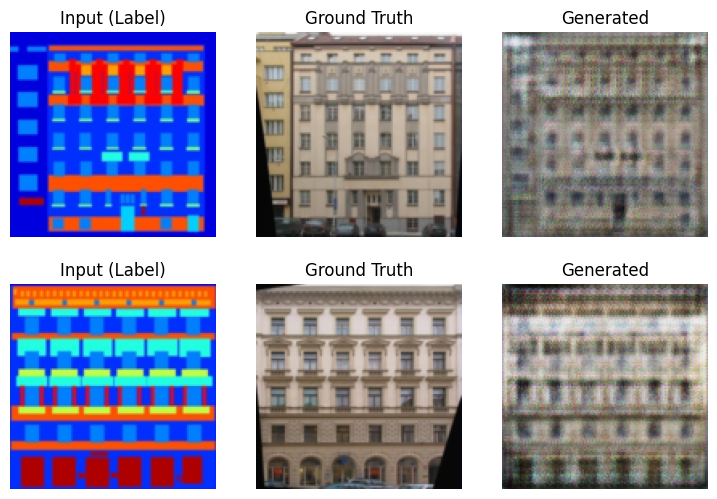

Epoch 25/40 | D 0.412 | G 24.798
Epoch 30/40 | D 0.319 | G 23.492
Epoch 35/40 | D 0.482 | G 24.671
Epoch 40/40 | D 0.564 | G 19.990


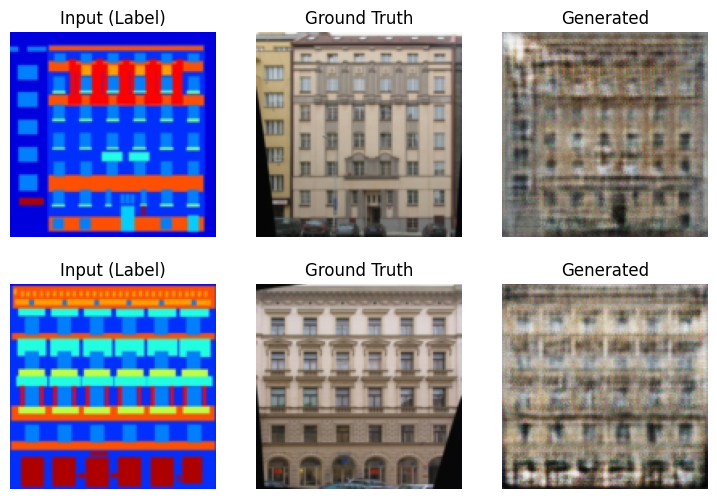

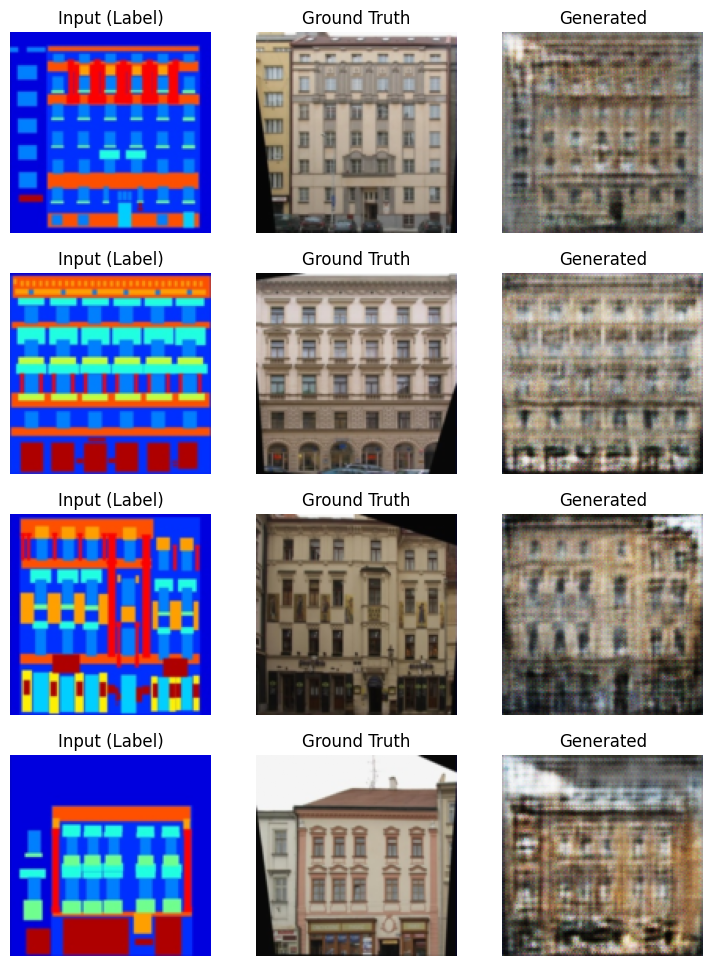

Model saved: pix2pix_generator.pth


In [ ]:
import os, glob, urllib.request, tarfile
import torch, torch.nn as nn, torch.optim as optim
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)
SIZE, BATCH, EPOCHS, LAMBDA = 128, 16, 40, 100

# ---------- Download dataset ----------
if not os.path.exists("facades"):
    urllib.request.urlretrieve(
        "http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/facades.tar.gz", "facades.tar.gz")
    tarfile.open("facades.tar.gz").extractall(".")

# ---------- Load everything into memory once (fast) ----------
tf = T.Compose([T.Resize((SIZE, SIZE)), T.ToTensor(), T.Normalize((0.5,) * 3, (0.5,) * 3)])

def load_split(folder):
    X, Y = [], []
    for f in sorted(glob.glob(f"facades/{folder}/*.jpg")):
        img = Image.open(f).convert("RGB")
        w, h = img.size
        Y.append(tf(img.crop((0, 0, w // 2, h))))   # real photo
        X.append(tf(img.crop((w // 2, 0, w, h))))   # label map
    return torch.stack(X).to(device), torch.stack(Y).to(device)

train_X, train_Y = load_split("train")
test_X, test_Y = load_split("test")
print("Train:", len(train_X), "| Test:", len(test_X))

# ---------- Generator (light U-Net) ----------
def down(i, o, norm=True):
    l = [nn.Conv2d(i, o, 4, 2, 1, bias=False)]
    if norm: l.append(nn.BatchNorm2d(o))
    return nn.Sequential(*l, nn.LeakyReLU(0.2))

def up(i, o, drop=False):
    l = [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o)]
    if drop: l.append(nn.Dropout(0.5))
    return nn.Sequential(*l, nn.ReLU())

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.d1 = down(3, 32, False); self.d2 = down(32, 64);  self.d3 = down(64, 128)
        self.d4 = down(128, 256);     self.d5 = down(256, 256); self.d6 = down(256, 256)
        self.d7 = down(256, 256, False)
        self.u1 = up(256, 256, True); self.u2 = up(512, 256, True); self.u3 = up(512, 256)
        self.u4 = up(512, 128);       self.u5 = up(256, 64);        self.u6 = up(128, 32)
        self.out = nn.Sequential(nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())
    def forward(self, x):
        d1 = self.d1(x); d2 = self.d2(d1); d3 = self.d3(d2); d4 = self.d4(d3)
        d5 = self.d5(d4); d6 = self.d6(d5); d7 = self.d7(d6)
        u = self.u1(d7)
        u = self.u2(torch.cat([u, d6], 1)); u = self.u3(torch.cat([u, d5], 1))
        u = self.u4(torch.cat([u, d4], 1)); u = self.u5(torch.cat([u, d3], 1))
        u = self.u6(torch.cat([u, d2], 1))
        return self.out(torch.cat([u, d1], 1))

# ---------- Discriminator (PatchGAN) ----------
class PatchGAN(nn.Module):
    def __init__(self):
        super().__init__()
        def blk(i, o, s, norm=True):
            l = [nn.Conv2d(i, o, 4, s, 1, bias=False)]
            if norm: l.append(nn.BatchNorm2d(o))
            return l + [nn.LeakyReLU(0.2)]
        self.net = nn.Sequential(*blk(6, 32, 2, False), *blk(32, 64, 2),
                                 *blk(64, 128, 2), *blk(128, 256, 1),
                                 nn.Conv2d(256, 1, 4, 1, 1))
    def forward(self, x, y):
        return self.net(torch.cat([x, y], 1))

G, D = UNet().to(device), PatchGAN().to(device)
opt_G = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce, l1 = nn.BCEWithLogitsLoss(), nn.L1Loss()

# ---------- Visualize ----------
def show_samples(n=4):
    G.eval()
    with torch.no_grad():
        fake = G(test_X[:n]).cpu()
    plt.figure(figsize=(9, 3 * n))
    for k in range(n):
        for j, (im, t) in enumerate([(test_X[k].cpu(), "Input (Label)"),
                                     (test_Y[k].cpu(), "Ground Truth"),
                                     (fake[k], "Generated")]):
            plt.subplot(n, 3, k * 3 + j + 1)
            plt.imshow((im.permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))
            plt.title(t); plt.axis("off")
    plt.show()
    G.train()

# ---------- Train ----------
N = len(train_X)
for epoch in range(1, EPOCHS + 1):
    perm = torch.randperm(N, device=device)
    for b in range(0, N, BATCH):
        idx = perm[b:b + BATCH]
        inp, real = train_X[idx], train_Y[idx]
        if torch.rand(1).item() > 0.5:                 # random flip
            inp, real = inp.flip(-1), real.flip(-1)

        # Discriminator
        fake = G(inp)
        d_real, d_fake = D(inp, real), D(inp, fake.detach())
        loss_D = 0.5 * (bce(d_real, torch.ones_like(d_real)) +
                        bce(d_fake, torch.zeros_like(d_fake)))
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()

        # Generator
        d_fake = D(inp, fake)
        loss_G = bce(d_fake, torch.ones_like(d_fake)) + LAMBDA * l1(fake, real)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

    if epoch % 5 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | D {loss_D.item():.3f} | G {loss_G.item():.3f}")
    if epoch % 20 == 0:
        show_samples(2)

# ---------- Final results & save ----------
show_samples(4)
torch.save(G.state_dict(), "pix2pix_generator.pth")
print("Model saved: pix2pix_generator.pth")